# Lesson 4: The emulator in JAX

The NumPy network of Lesson 3 learns, but slowly, and every new idea (a different activation, a new layer type) means deriving and coding a new backward pass. Three upgrades fix this:

1. **JAX** computes gradients automatically and compiles the code.
2. **Adam**, a better optimizer than plain gradient descent.
3. **A learning-rate schedule**: big steps early, small steps late.

Then we use short runs to make choices one at a time, train the final emulator, and save it. The code is in `emulator/jax_mlp.py`.

Running the whole notebook takes about 10 minutes on a laptop.

In [1]:
# 1. Let Python find the emulator package
import sys

sys.path.insert(0, "..")

# 2. Imports
import inspect
import json
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from emulator import data, evaluate, jax_mlp, numpy_mlp
from emulator.evaluate import PALETTE

## 1. JAX in three ideas

The module `jax.numpy` mirrors NumPy: almost every NumPy function exists in `jnp` with the same name and behaviour.

The function `jax.grad` turns a function into its derivative. You write the function, and JAX traces every operation in it and applies the chain rule for you, exactly as we did by hand in Lesson 3.

In [2]:
# 1. A function and its derivative
def cube(x):
    """Return x**3 (a one-line example for jax.grad).

    Parameters
    ----------
    x : float
        Input.

    Returns
    -------
    value : float
        x cubed.
    """
    value = x**3
    return value


derivative = jax.grad(cube)
print("f(2) =", cube(2.0), "   f'(2) =", derivative(2.0), "   (exact: 3 * 2**2 = 12)")

f(2) = 8.0    f'(2) = 12.0    (exact: 3 * 2**2 = 12)


The function `jax.jit` compiles a function, so the first call is slow (JAX traces the function and compiles it for your CPU or GPU) and later calls are faster. Here is the gradient of the loss for one batch of 1024 models, the core of a training step:

In [3]:
# 1. The gradient on one batch, without and with compilation
params = jax_mlp.init_params([6, 256, 256, 256, 19], seed=0)
x_batch = jnp.ones((1024, 6))
y_batch = jnp.zeros((1024, 19))
gradient = jax.grad(jax_mlp.loss_fn)
gradient_compiled = jax.jit(gradient)

# 2. Time 20 calls of each, after a first call (which compiles, for jit)
for name, function in [("plain", gradient), ("jit", gradient_compiled)]:
    jax.block_until_ready(function(params, x_batch, y_batch))
    start = time.perf_counter()
    for repeat in range(20):
        jax.block_until_ready(function(params, x_batch, y_batch))
    print(f"{name:5s}: {1e3 * (time.perf_counter() - start) / 20:.2f} ms per gradient")

plain: 6.87 ms per gradient
jit  : 3.39 ms per gradient


On a laptop CPU the gain is about a factor of two, because most of the time goes into a few large matrix products that are fast either way. The gain grows on a GPU and for functions made of many small operations, such as the Adam update, which is why the training step in `jax_mlp.py` is compiled. (`block_until_ready` makes the timing honest, because JAX returns before the work is finished unless you ask it to wait.)

## 2. The same network, with automatic gradients

`jax_mlp.forward` and `jax_mlp.loss_fn` are the NumPy functions of Lesson 3 with `np` replaced by `jnp`. There is no backward function: `jax.grad(jax_mlp.loss_fn)` is the backward pass. Check that it agrees with our hand-written one, starting from the same weights:

In [4]:
# 1. Load and transform the data (as before)
grid = data.load_grid("../training_250k.h5")
inputs, outputs, output_names = grid["inputs"], grid["outputs"], grid["output_names"]
indices = data.split_from_labels(grid["split"])
train, val = indices["train"], indices["val"]
input_transform = data.fit_input_transform(inputs[train])
output_transform = data.fit_output_transform(outputs[train])
x_train = data.transform_inputs(inputs[train], input_transform)
x_val = data.transform_inputs(inputs[val], input_transform)
y_train = data.transform_outputs(outputs[train], output_transform)
y_val = data.transform_outputs(outputs[val], output_transform)

# 2. Gradients on one batch: by hand (NumPy, Lesson 3) and by JAX
x_batch, y_batch = x_train[:256], y_train[:256]
numpy_params = numpy_mlp.init_params([6, 64, 64, 19], seed=0)
y_pred, activations = numpy_mlp.forward(numpy_params, x_batch)
by_hand = numpy_mlp.backward(numpy_params, activations, y_pred, y_batch)

jax_params = jax_mlp.init_params([6, 64, 64, 19], seed=0)
by_jax = jax.grad(jax_mlp.loss_fn)(
    jax_params, jnp.asarray(x_batch, jnp.float32), jnp.asarray(y_batch, jnp.float32)
)

# 3. Compare
for number, (hand, auto) in enumerate(zip(by_hand, by_jax), start=1):
    for key in ("W", "b"):
        relative = (
            np.abs(np.asarray(auto[key]) - hand[key]).max() / np.abs(hand[key]).max()
        )
        print(f"layer {number} {key}: relative difference {relative:.1e}")

layer 1 W: relative difference 3.8e-07
layer 1 b: relative difference 3.9e-07
layer 2 W: relative difference 3.3e-07
layer 2 b: relative difference 2.2e-07
layer 3 W: relative difference 5.3e-07
layer 3 b: relative difference 2.4e-07


The two agree to about 1e-7, the precision of float32 numbers (JAX's default, whereas NumPy used float64), so from here on we never write a backward pass again.

## 3. Adam

Plain gradient descent uses one step size for every weight. But the gradient of some weights is a thousand times larger than that of others, so one learning rate is too big for some and too small for the rest. **Adam** keeps two running averages for every weight, of the gradient (which direction) and of the squared gradient (how big the gradients usually are), and divides one by the square root of the other. Every weight then moves by roughly the learning rate per step, whatever the size of its gradient:

In [5]:
print(inspect.getsource(jax_mlp.adam_update).split('"""')[2])


    # 1. Update the running averages
    step = state["step"] + 1
    m = jax.tree_util.tree_map(
        lambda m_, g: beta1 * m_ + (1 - beta1) * g, state["m"], grads
    )
    v = jax.tree_util.tree_map(
        lambda v_, g: beta2 * v_ + (1 - beta2) * g**2, state["v"], grads
    )

    # 2. Bias corrections for the first few steps
    m_correction = 1 - beta1**step
    v_correction = 1 - beta2**step

    # 3. Move every weight
    new_params = jax.tree_util.tree_map(
        lambda w, m_, v_: w
        - learning_rate * (m_ / m_correction) / (jnp.sqrt(v_ / v_correction) + epsilon),
        params,
        m,
        v,
    )
    new_state = {"m": m, "v": v, "step": step}

    return new_params, new_state



Same network, same starting weights, ten epochs each:

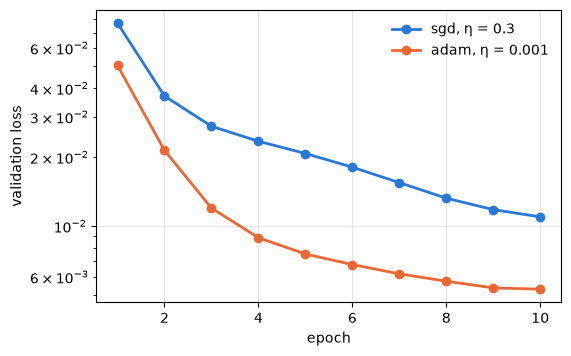

In [6]:
# 1. Plain SGD (Lesson 3's best learning rate) against Adam (its usual default)
fig, ax = plt.subplots(figsize=(6, 3.8))
for colour, (optimizer, learning_rate) in zip(PALETTE, [("sgd", 0.3), ("adam", 1e-3)]):
    params = jax_mlp.init_params([6, 64, 64, 19], seed=0)
    _, history = jax_mlp.train(
        params,
        x_train,
        y_train,
        x_val,
        y_val,
        n_epochs=10,
        batch_size=256,
        lr_start=learning_rate,
        lr_end=learning_rate,
        optimizer=optimizer,
        print_every=0,
    )
    ax.plot(
        np.arange(1, 11),
        history["val_loss"],
        "o-",
        color=colour,
        lw=2,
        label=f"{optimizer}, η = {learning_rate}",
    )

# 2. Labels
ax.set(xlabel="epoch", ylabel="validation loss", yscale="log")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()

## 4. The learning-rate schedule

Early in training the weights are far from good and big steps help. Late in training, big steps make the loss bounce around the bottom of the valley instead of settling into it, so the learning rate is lowered over the run. We use a **cosine schedule**: it starts at 1e-3 and glides down to 1e-5 along half a cosine.

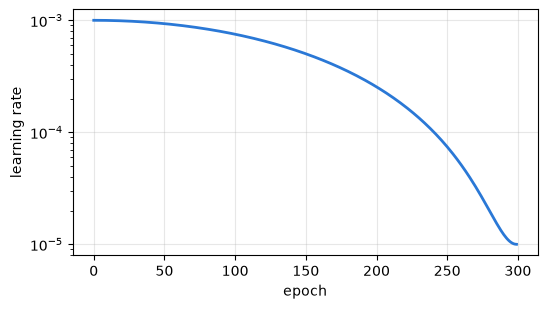

In [7]:
# 1. The schedule for a 300-epoch run
epochs = np.arange(300)
rates = [jax_mlp.cosine_learning_rate(epoch, 300) for epoch in epochs]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(epochs, rates, color=PALETTE[0], lw=2)
ax.set(xlabel="epoch", ylabel="learning rate", yscale="log")
ax.grid(alpha=0.3)
plt.show()

The function `jax_mlp.train` puts all of this together: every epoch it shuffles the training set, takes one Adam step per batch of 1024 models, computes the validation loss, and **keeps the weights with the lowest validation loss** seen so far. That last part protects against overfitting: if the validation loss started to rise, we would still return the best weights.

## 5. Choosing settings with short runs

There are many choices: network width and depth, activation, floor, batch size, how to present the inputs. The way to choose is to **change one thing at a time** and compare validation errors, using short runs (here 40 epochs) so each test costs well under a minute. Short runs give the ranking, and the final run then trains longer.

We test two ideas from Lesson 1:

- **Raise the floor from 1e-30 to 1e-15.** The network stops spending effort on abundances below 1e-15, which no spectrum can detect.
- **Give the network 1000/T instead of log10 T**, since log abundances are straight lines in 1/T below condensation.

In [8]:
# 1. The three variants: (label, floor, use 1/T)
variants = [
    ("reference: floor 1e-30, log T", -30.0, False),
    ("floor 1e-15", -15.0, False),
    ("1000/T instead of log T", -30.0, True),
]
short_run_scores = {}

for label, log10_floor, use_inverse_temperature in variants:

    # 1a. Inputs for this variant
    features = inputs.copy()
    if use_inverse_temperature:
        features[:, 0] = 1000.0 / 10.0 ** inputs[:, 0]
    variant_input_transform = data.fit_input_transform(features[train])
    variant_output_transform = data.fit_output_transform(
        outputs[train], log10_floor=log10_floor
    )

    # 1b. Train for 40 epochs
    params = jax_mlp.init_params([6, 256, 256, 256, 19], seed=0)
    params, history = jax_mlp.train(
        params,
        data.transform_inputs(features[train], variant_input_transform),
        data.transform_outputs(outputs[train], variant_output_transform),
        data.transform_inputs(features[val], variant_input_transform),
        data.transform_outputs(outputs[val], variant_output_transform),
        n_epochs=40,
        batch_size=1024,
        print_every=0,
    )

    # 1c. Validation errors in dex, on the abundances that matter
    x_variant = data.transform_inputs(features[val], variant_input_transform)
    log10_pred = data.inverse_transform_outputs(
        np.asarray(jax_mlp.forward(params, x_variant)), variant_output_transform
    )
    short_run_scores[label] = evaluate.summary_errors(outputs[val], log10_pred)
    print(
        f"{label:30s} median {short_run_scores[label]['median']:.4f} dex   99% {short_run_scores[label]['p99']:.3f} dex   ({sum(history['seconds']):.0f} s)"
    )

reference: floor 1e-30, log T  median 0.0833 dex   99% 0.740 dex   (31 s)


floor 1e-15                    median 0.0559 dex   99% 0.548 dex   (32 s)


1000/T instead of log T        median 0.1566 dex   99% 1.296 dex   (32 s)


Raising the floor from 1e-30 to 1e-15 lowers the errors. The species that spend half the grid on the floor now have a smaller spread, so the standardized loss pays more attention to the part of their range that matters, and the network has a shorter cliff to climb.

Using 1000/T instead of log10 T raises the errors, even though the physics is simpler in 1/T. Lesson 1's TiO plot showed why: the grid is uniform in log T, so in 1/T everything hotter than about 800 K is squeezed into a tenth of the input range, and the network needs very steep features there. Whether a transform helps depends on the data as well as the physics, which is why every idea gets a short run. (Feeding both log T and 1/T, as a seventh input, gives the same errors as log T alone.)

## 6. The final emulator

Settings: floor 1e-15, inputs as in the grid, three hidden layers of 256 units with tanh, Adam with the cosine schedule from 1e-3 to 1e-5, batches of 1024, 300 epochs.

In [9]:
# 1. Transforms for the final emulator
LOG10_FLOOR = -15.0
LAYER_SIZES = [6, 256, 256, 256, 19]
N_EPOCHS = 300

input_transform = data.fit_input_transform(inputs[train])
output_transform = data.fit_output_transform(outputs[train], log10_floor=LOG10_FLOOR)
x_train = data.transform_inputs(inputs[train], input_transform)
x_val = data.transform_inputs(inputs[val], input_transform)
y_train = data.transform_outputs(outputs[train], output_transform)
y_val = data.transform_outputs(outputs[val], output_transform)

# 2. Train
params = jax_mlp.init_params(LAYER_SIZES, seed=0)
print("trainable numbers:", numpy_mlp.count_params(params))
params, history = jax_mlp.train(
    params,
    x_train,
    y_train,
    x_val,
    y_val,
    n_epochs=N_EPOCHS,
    batch_size=1024,
    print_every=25,
)

trainable numbers: 138259


epoch    0  lr 1.0e-03  train 2.23e-01  val 4.67e-02  (0.9 s)


epoch   25  lr 9.8e-04  train 1.88e-03  val 1.93e-03  (0.8 s)


epoch   50  lr 9.3e-04  train 1.23e-03  val 1.29e-03  (0.8 s)


epoch   75  lr 8.5e-04  train 9.12e-04  val 9.76e-04  (0.9 s)


epoch  100  lr 7.5e-04  train 7.27e-04  val 7.97e-04  (0.9 s)


... (4 outputs left out)

epoch  225  lr 1.5e-04  train 3.60e-04  val 4.51e-04  (0.9 s)


epoch  250  lr 7.4e-05  train 3.32e-04  val 4.19e-04  (0.8 s)


epoch  275  lr 2.6e-05  train 3.17e-04  val 4.07e-04  (0.8 s)


epoch  299  lr 1.0e-05  train 3.12e-04  val 3.99e-04  (0.9 s)


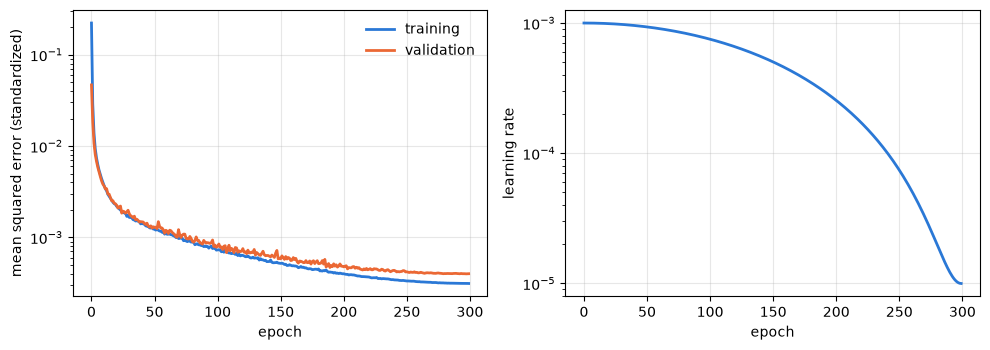

In [10]:
fig = evaluate.plot_history(history)
plt.show()

The two losses track each other for the first 50 epochs and then separate slowly, and by the end the validation loss sits about 30% above the training loss. The network has started to fit details of the training models that do not carry over to new ones, which is mild overfitting. It does no harm here, because the validation loss keeps falling to the last epoch and `train` returns the weights with the lowest validation loss. The steady drop as the learning rate shrinks is the schedule at work.

Validation errors, species by species, counting only abundances above 1e-12:

In [11]:
# 1. Predictions on the validation set, back in dex
log10_pred = data.inverse_transform_outputs(
    np.asarray(jax_mlp.forward(params, jnp.asarray(x_val, jnp.float32))),
    output_transform,
)

# 2. Per-species table
stats = evaluate.error_statistics(
    outputs[val], log10_pred, output_names, threshold=-12.0
)
print(
    evaluate.format_error_table(
        stats, "validation set, where the true or predicted VMR > 1e-12"
    )
)

validation set, where the true or predicted VMR > 1e-12
output         n   median      95%      99%      max  [dex]
H           9803   0.0197   0.0761   0.1219    0.218
H2         25000   0.0015   0.0079   0.0157    0.200
H-          4491   0.0129   0.0451   0.0658    0.137
e-          7284   0.0171   0.0657   0.1090    0.360
He         25000   0.0002   0.0010   0.0021    0.010
H2O        20123   0.0234   0.1028   0.1979    2.705
CO         11936   0.0211   0.0813   0.1294    0.803
CO2        11097   0.0255   0.1046   0.2223    2.593
CH4        21990   0.0170   0.0762   0.1693    2.738
C2H2        3597   0.0372   0.2455   0.7472    6.153
Fe          8000   0.0286   0.1263   0.2148    0.403
TiO         5402   0.0331   0.2042   0.3788    4.089
SiO         7688   0.0405   0.1938   0.3684    1.574
HCN         7730   0.0226   0.1125   0.3068    2.614
NH3        20741   0.0244   0.1242   0.2995    6.597
N2         15387   0.0236   0.0942   0.1579    0.518
H2S        17661   0.0495   0.3639  

In [12]:
# 1. Compare with everything so far
with open("../runs/baseline_scores.json") as handle:
    scores = json.load(handle)
scores[f"JAX emulator, {N_EPOCHS} epochs"] = evaluate.summary_errors(
    outputs[val], log10_pred
)
for name, score in scores.items():
    print(f"{name:30s} median {score['median']:.4f} dex   99% {score['p99']:.3f} dex")

mean                           median 9.5135 dex   99% 15.398 dex
polynomial, degree 1           median 3.3587 dex   99% 8.094 dex
polynomial, degree 2           median 2.5986 dex   99% 7.081 dex
polynomial, degree 3           median 1.4586 dex   99% 4.636 dex
polynomial, degree 4           median 0.9077 dex   99% 3.619 dex
polynomial, degree 5           median 0.7193 dex   99% 3.029 dex
nearest neighbours, k=1        median 0.3736 dex   99% 5.694 dex
nearest neighbours, k=8        median 0.2910 dex   99% 3.008 dex
nearest neighbours, k=32       median 0.3979 dex   99% 2.900 dex
JAX emulator, 300 epochs       median 0.0222 dex   99% 0.247 dex


## 7. Save the emulator

The emulator is the weights **plus** the input and output transforms (forgetting the transforms is the most common emulator bug). `save_emulator` writes all of it into one `.npz` file of plain NumPy arrays.

In [13]:
jax_mlp.save_emulator(
    "../runs/emulator.npz",
    params,
    input_transform,
    output_transform,
    grid["input_names"],
    output_names,
    activation="tanh",
)
print("saved ../runs/emulator.npz")

saved ../runs/emulator.npz


Lesson 5 loads this file, tests it on the 25,000 test models, and uses it on atmosphere profiles.

## Exercises

1. Make the network wider (512) or deeper (4 hidden layers) in a 40-epoch run. Which helps more per extra second of training?
2. Try `activation="silu"` in a 40-epoch run.
3. Try a floor of 1e-20. Where between -30 and -15 do the gains come from?
4. Change the batch size to 256 and to 4096 (with the same number of epochs). What happens to the time per epoch and to the error?
5. Train with `optimizer="sgd"` and the cosine schedule from 0.3 to 0.003 for 40 epochs. How far behind Adam is it?